# Evolutionäre Algorithmen – Diskrete Optimierungsprobleme

## Szenario: Rucksackproblem und Varianten

In diesem Notebook verwenden wir **Evolutionäre Algorithmen**, um diskrete Optimierungsprobleme zu lösen.

Zunächst betrachten wir das klassische **Knapsack-Problem**:

> Welche Gegenstände sollten ausgewählt werden, damit ihr Gesamtwert möglichst groß ist, ohne eine vorgegebene Gewichtskapazität zu überschreiten?

Anschließend verändern wir das Problem und betrachten eine abgewandelte Fragestellung:

> Wie können Gegenstände auf möglichst wenige Boxen verteilt werden, wenn jede Box nur eine begrenzte Kapazität besitzt?

Für die Implementierung verwenden wir die Python-Bibliothek `DEAP`.

> **Wichtig:** Die Qualität eines evolutionären Algorithmus hängt nicht nur vom verwendeten Algorithmus ab. Entscheidend ist auch, **wie eine Lösung kodiert wird und wie die Fitnessfunktion einschließlich möglicher Nebenbedingungen definiert ist**.

## Lernziele

1. ein Optimierungsproblem als **Maximierungs- oder Minimierungsproblem** klassifizieren,

2. erklären, wie Lösungen als **Individuen bzw. Genome** kodiert werden und eine geeignete **Fitnessfunktion** für ein diskretes Optimierungsproblem definieren,

3. verstehen, wie **Constraints** mit Hilfe einer Penalty in die Fitnessbewertung einbezogen werden können,

4. das `DEAP`Framework für die Implementierung verwenden,

5. nachvollziehen, warum wiederholte Läufe aufgrund zufälliger Prozesse unterschiedliche Lösungen liefern können,

6. einen vorhandenen evolutionären Algorithmus auf eine **veränderte Problemstellung** übertragen,

7. erkennen, dass unterschiedliche Problemrepräsentationen auch unterschiedliche **Genkodierungen und Mutationsoperatoren** benötigen,

## Ablauf

Das Notebook gliedert sich in drei Schritte:

**1. Knapsack-Problem analysieren**  
Untersuchen Sie die gegebene Implementierung, die Kodierung der Individuen, die Fitnessfunktion und die Behandlung der Gewichtsbeschränkung.

**2. Knapsack-Problem anpassen**  
Übertragen Sie die Implementierung auf ein weiteres Rucksackproblem und analysieren Sie die gefundene Lösung.

**3. Vom Knapsack zu einem neuen Problem**  
Verändern Sie Zielsetzung, Kodierung und Fitnessfunktion so, dass Gegenstände auf möglichst wenige Boxen mit begrenzter Kapazität verteilt werden.


# 1. Knapsack-Problem analysieren

Machen Sie sich mit untenstehendem Code vertraut, der das Knapsack Problem löst:

- Welche Aufgabe wird gelöst?
- Handelt es sich um ein Minimierungs- oder Maximierungs-Problem?
- Wie werden `ITEMS` definiert?
- Wie ist eine Lösung kodiert?
- Wie werden `total_value()` und `total_weight()` definiert?
- Was macht die Penalty in `evaluate()`?



### TODO



Führen Sie dann den Code aus und betrachten und plausibilisieren Sie die Lösung! Erhalten Sie bei wiederholten Läufen dasselbe Ergebnis?

gen	nevals	avg     	min   	max
0  	25    	-8973.64	-28893	52 
1  	21    	-2867.56	-14922	52 
2  	24    	-33.52  	-1946 	52 
3  	20    	50.04   	36    	52 
4  	21    	51.2    	45    	52 
5  	23    	51.76   	49    	52 
6  	24    	52      	52    	52 
7  	24    	52      	52    	52 
8  	22    	52      	52    	52 
9  	24    	52      	52    	52 
10 	21    	52      	52    	52 
11 	22    	52      	52    	52 
12 	20    	52      	52    	52 
13 	21    	52      	52    	52 
14 	25    	52      	52    	52 
15 	21    	52      	52    	52 
16 	23    	52      	52    	52 
17 	23    	52      	52    	52 
18 	24    	52.16   	52    	54 
19 	22    	51.32   	27    	54 
20 	22    	52.4    	52    	54 
21 	22    	53.04   	52    	54 
22 	22    	53.92   	52    	54 
23 	22    	54      	54    	54 
24 	23    	54      	54    	54 
25 	21    	54      	54    	54 
26 	23    	53.64   	45    	54 
27 	24    	54      	54    	54 
28 	22    	54      	54    	54 
29 	22    	54      	54    	54 
30 	23    	54      	54    	54 
31 	22  

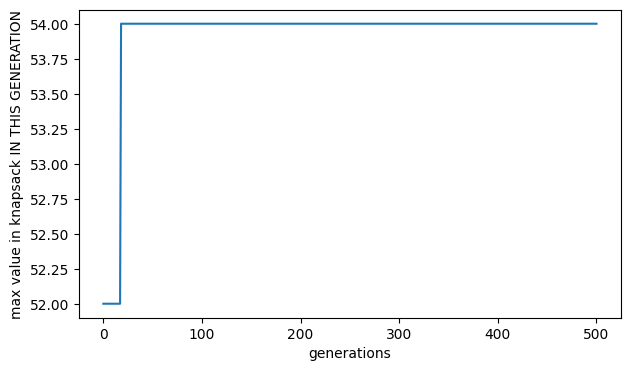

In [4]:
import random
from deap import base, creator, tools, algorithms
import matplotlib.pyplot as plt

# ----------------------------
# Daten
# ----------------------------
ITEMS = [ #(value, weight)
    (10, 5), (7, 3), (25, 12), (15, 8), (6, 3),
    (18,10), (3, 1), (12, 6), (14, 7), (9, 4)
]
CAPACITY = 25
N_ITEMS = len(ITEMS)
#SEED = 42
#random.seed(SEED)

# ----------------------------
# DEAP: Klassen & Toolbox
# ----------------------------
creator.create("FitnessMax", base.Fitness, weights=(1.0,))
creator.create("Individual", list, fitness=creator.FitnessMax)

toolbox = base.Toolbox()
toolbox.register("attr_bool", random.randint, 0, 1)
toolbox.register("individual", tools.initRepeat, creator.Individual, toolbox.attr_bool, n=N_ITEMS)
toolbox.register("population", tools.initRepeat, list, toolbox.individual)

def total_value(individual):
    # Berechne den Gesamtwert der ausgewählten Items.
    total = 0
    for i in range(len(individual)):
        if individual[i] == 1:   # Item ist ausgewählt
            total += ITEMS[i][0] # 0 = Wert
    return total


def total_weight(individual):
    # Berechne das Gesamtgewicht der ausgewählten Items.
    total = 0
    for i in range(len(individual)):
        if individual[i] == 1:    # Item ist ausgewählt
            total += ITEMS[i][1]  # 1 = Gewicht
    return total

# Strafe pro überschrittene Gewichtseinheit
PENALTY_COEF = 1000  # Strafe pro überschrittene Gewichtseinheit

def evaluate(ind):
    v = total_value(ind)
    overweight = max(0, total_weight(ind) - CAPACITY)
    if overweight > 0:
        # Reduziere Fitness falls Kapazitäteneinschränkung missachtet
        v -= PENALTY_COEF * overweight
    return (v,)

toolbox.register("evaluate", evaluate)
toolbox.register("mate", tools.cxTwoPoint)
toolbox.register("mutate", tools.mutFlipBit, indpb=1.0 / N_ITEMS)
toolbox.register("select", tools.selTournament, tournsize=3)

def run(pop_size=25, cxpb=0.7, mutpb=0.2, ngen=500, halloffame_k=1):
    pop = toolbox.population(n=pop_size)
    hof = tools.HallOfFame(halloffame_k)

    stats = tools.Statistics(lambda ind: ind.fitness.values[0])
    stats.register("avg", lambda xs: sum(xs)/len(xs))
    stats.register("min", min)
    stats.register("max", max)

    # EA ohne Eliten-Beibehaltung über Generationen
    '''
    pop, log = algorithms.eaSimple(
        pop, toolbox, cxpb=cxpb, mutpb=mutpb, ngen=ngen,
        stats=stats, halloffame=hof, verbose=True
    )
    '''
    
    # EA, der die mu besten Lösungen beibehält:
    pop, log = algorithms.eaMuPlusLambda(
        pop, toolbox, mu=pop_size, lambda_=pop_size,
        cxpb=cxpb, mutpb=mutpb, ngen=ngen, 
        stats=stats, halloffame=hof, verbose=True
    )

    best = hof[0]
    return best, log

if __name__ == "__main__":
    best, log = run()
    print("\nBeste Lösung (0/1-Vektor):", list(best))
    print(f"Gesamtwert = {total_value(best)}, Gesamtgewicht = {total_weight(best)} / Kapazität {CAPACITY}")
    
    # plotting:
    gens = log.select("gen")
    maxs = log.select("max")
    plt.figure(figsize=(7,4))
    plt.plot(gens, maxs, label="Max")
    plt.xlabel("generations")
    plt.ylabel("max value in knapsack IN THIS GENERATION")

# 2. Knapsack-Problem anpassen

Wandeln Sie den Code nun ab, um dem Dieb aus dem Skript zu helfen!

In [ ]:
## TODO




# 3. Vom Knapsack zu einem neuen Problem

Nun wenden wir uns einem neuen Problem zu:

Die Aufgabe besteht nun darin, Gegenstände mit unterschiedlichen Gewichten in möglichst wenige Boxen zu packen. Jede Box hat dabei ein maximales Zuladungsgewicht von 12kg. 

Gehen Sie wie folgt vor:
- Machen Sie sich klar, ob es sich um ein Minimierungs- oder Maximierungsproblem handelt. Was bedeutet das für die Definition via creator? Was für die Penalty?
- Definieren Sie neue `ITEMS` wie folgt:

>  ITEMS = [(5), (3), (12), (8), (3), (10), (1), (2), (5), (4)] (die Zahlen sind die Itemgewichte)

- Wie kann die neue Initialisierung aussehen?
- Wie könnte die `total_value()` Funktion aussehen?
- Wie könnte die `total_weight()` Funktion aussehen?
- Was bedeutet das für die `evaluate()`-Funktion?
- Wie können Sie die mutate Funktion anpassen? Hinweis: Nutzen Sie `tools.mutUniformInt()`
- Passen Sie die Ausgabe an

TODO: Vorüberlegungen



In [ ]:
# TODO: Code



*Quellenhinweis*: Bei der Formattierung der Einleitung dieses Notebooks wurde ChatGPT-5.1 verwendet.